# ICA06 — Working with nested and restart simulations 

This notebook is a streamlined introduction to comparing nesting geometries and how to compare simulations when grids differ

Julie.Lundquist@JHU.edu
2026 February (updated from 2023 version)

## Learning goals
By the end, you should be able to:
1. Pick variables: **RAINNC** (accumulated precip) and **wind** (10 m wind speed WS10 = √(U10²+V10²))
2. Open one wrfout_d01_... and one wrfout_d02_... at the same valid time
3. Compute the d02 lat/lon bounds; subset d01 to the overlapping region
4. Plot contours of each variable for d01-overlap and d02 side-by-side (common colorbar) to identify the (subtle) differences
5. Pick a point (lat0, lon0) in d02; find nearest gridpoint in each domain
6. Use ncks to extract a time series at that point across all times for d01 and d02 (for RAINNC); for wind, compute WS10 time series in Python from U10, V10
7. Plot the two time series for each variable; discuss differences if any

In [1]:

# --- Imports ---
import numpy as np
import pandas as pd
import xarray as xr
import re
from pathlib import Path


import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

from pathlib import Path
import glob
import subprocess
import shlex


from matplotlib.axes import Axes # Makes the color bar easier to work with
from mpl_toolkits.axes_grid1 import make_axes_locatable # Color bar location
import matplotlib.ticker as mticker


from matplotlib.colors import ListedColormap, BoundaryNorm # Because I'm particular about color tables
from matplotlib.colors import Normalize # Because I'm particular about color tables
from matplotlib.colors import TwoSlopeNorm # to help normalize map factors so color table is centered on zero



print("Imports OK")

Imports OK


In [2]:
# -------------------------
# STUDENT: edit these
# -------------------------

CASE_DIR = Path("wrfout")  # folder containing wrfout_d01_* and wrfout_d02_*

time_str = "2005-08-29_12_00_00"       # pick one valid time string (use underscores as in filenames)

# Variables used in this notebook: RAINNC (accumulated precip) and wind (WS10 = 10 m wind speed from U10, V10)
varname = "RAINNC"   # used for ncks extraction and one set of maps/time series

# point for timeseries (pick a point inside d02)
lat0 = 29.35
lon0 = -89.52


In [3]:
# Find matching d01 and d02 files for a chosen time

d01_file = sorted(CASE_DIR.glob(f"wrfout_d01_*{time_str}*"))
d02_file = sorted(CASE_DIR.glob(f"wrfout_d02_*{time_str}*"))

if len(d01_file) == 0 or len(d02_file) == 0:
    raise FileNotFoundError("Could not find matching wrfout files for the chosen time_str.")

# d01_file = d01_file[0]
# d02_file = d02_file[0]

# print("d01:", d01_file)
# print("d02:", d02_file)
d01_file

[WindowsPath('wrfout/wrfout_d01_2005-08-29_12_00_00')]

In [4]:
# Open the two files with xarray (d01_file and d02_file are lists from glob, so use [0])

ds1 = xr.open_dataset(d01_file[0])
ds2 = xr.open_dataset(d02_file[0])

# Lat/lon arrays
lat1 = ds1["XLAT"].isel(Time=0)
lon1 = ds1["XLONG"].isel(Time=0)
lat2 = ds2["XLAT"].isel(Time=0)
lon2 = ds2["XLONG"].isel(Time=0)

# bounds of d02 (overlap region)
bounds2 = [float(lon2.min()), float(lon2.max()), float(lat2.min()), float(lat2.max())]
bounds2


[-93.26752471923828,
 -81.75513458251953,
 21.628446578979492,
 30.614686965942383]

In [5]:
# Subset d01 to the d02 overlap region: This uses a mask rather than .sel() since WRF lat/lon are curvilinear.

mask_overlap = (
    (lat1 >= bounds2[2]) & (lat1 <= bounds2[3]) &
    (lon1 >= bounds2[0]) & (lon1 <= bounds2[1])
)

# --- Variable 1: RAINNC (accumulated precip) ---
v1_rain = ds1[varname].isel(Time=0).where(mask_overlap)
v2_rain = ds2[varname].isel(Time=0)
print(varname, "units:", ds1[varname].attrs.get("units", "unknown"))

# --- Variable 2: WS10 (10 m wind speed = sqrt(U10^2 + V10^2)) ---
U1 = ds1["U10"].isel(Time=0).where(mask_overlap)
V1 = ds1["V10"].isel(Time=0).where(mask_overlap)
v1_ws = np.sqrt(U1**2 + V1**2)

U2 = ds2["U10"].isel(Time=0)
V2 = ds2["V10"].isel(Time=0)
v2_ws = np.sqrt(U2**2 + V2**2)
print("WS10 units: m/s")


RAINNC units: mm
WS10 units: m/s


[OK] Saved figure → RAINNC_side_by_side.png


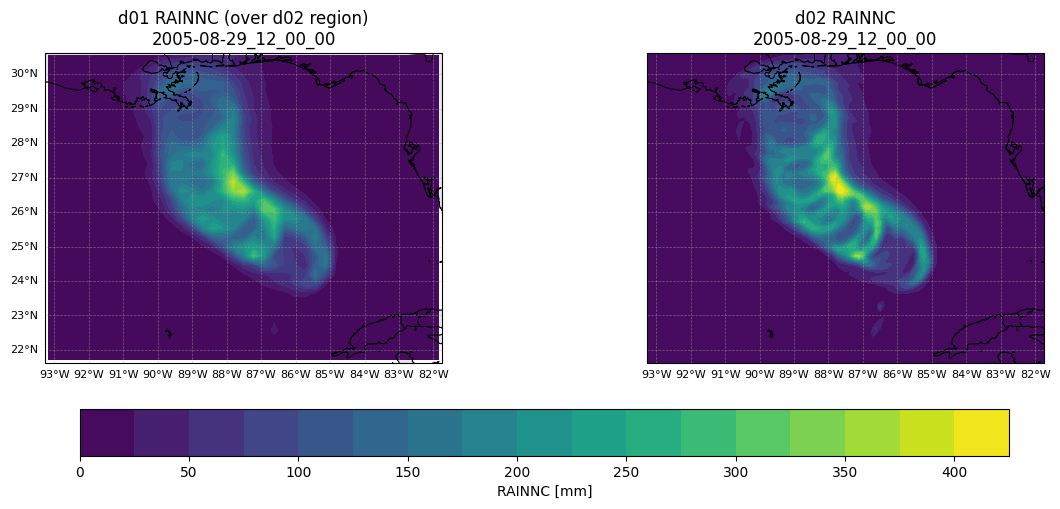

[OK] Saved figure → WS10_side_by_side.png


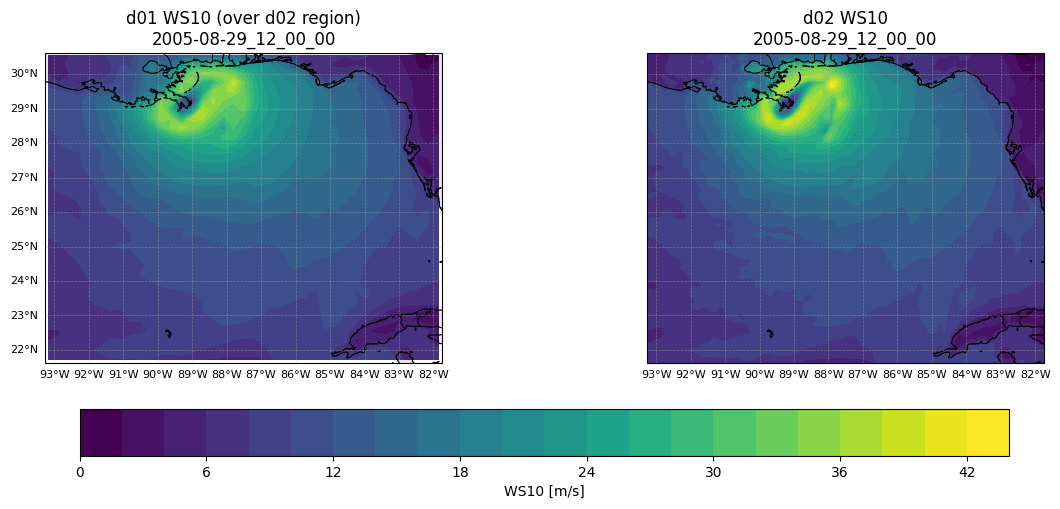

In [6]:
# Plot the two domains side-by-side for each variable (d02 region only for d01)

proj = ccrs.PlateCarree()

def plot_side_by_side(v1, v2, title_var, cbar_label, save_name):
    """Plot v1 (d01) and v2 (d02) side-by-side with shared colorbar."""
    vmin = float(np.nanmin([np.nanmin(v1.values), np.nanmin(v2.values)]))
    vmax = float(np.nanmax([np.nanmax(v1.values), np.nanmax(v2.values)]))

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 5),
        subplot_kw={"projection": proj},
        constrained_layout=True
    )

    for i, ax in enumerate(axes):
        ax.set_extent(bounds2, crs=proj)
        ax.add_feature(cfeature.LAND, facecolor="0.9", zorder=0)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
        ax.add_feature(cfeature.STATES, linewidth=0.4)
        gl = ax.gridlines(crs=proj, draw_labels=True, linewidth=0.5, linestyle="--", alpha=0.5)
        gl.top_labels = False
        gl.right_labels = False
        gl.left_labels = (i == 0)
        gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 1))
        gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 1))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.xlabel_style = {"size": 8}
        gl.ylabel_style = {"size": 8}

    cf1 = axes[0].contourf(lon1, lat1, v1, levels=20, vmin=vmin, vmax=vmax, transform=proj)
    axes[0].set_title(f"d01 {title_var} (over d02 region)\n{time_str}")

    cf2 = axes[1].contourf(lon2, lat2, v2, levels=20, vmin=vmin, vmax=vmax, transform=proj)
    axes[1].set_title(f"d02 {title_var}\n{time_str}")

    cbar = fig.colorbar(cf2, ax=axes, orientation="horizontal", pad=0.08)
    cbar.set_label(cbar_label)
    fig.savefig(save_name, dpi=200)
    print(f"[OK] Saved figure → {save_name}")
    plt.show()

# RAINNC
plot_side_by_side(v1_rain, v2_rain, varname, f"{varname} [mm]", f"{varname}_side_by_side.png")

# WS10 (10 m wind speed)
plot_side_by_side(v1_ws, v2_ws, "WS10", "WS10 [m/s]", "WS10_side_by_side.png")


In [21]:


def nearest_ij(lat2d, lon2d, lat0, lon0):
    # handle 0..360 lon if present
    lon = lon2d.values
    lat = lat2d.values
    lon0_use = lon0 % 360 if (np.nanmax(lon) > 180 and lon0 < 0) else lon0
    dist2 = (lat - lat0)**2 + (lon - lon0_use)**2
    j, i = np.unravel_index(np.nanargmin(dist2), dist2.shape)
    return int(j), int(i)

j1, i1 = nearest_ij(lat1, lon1, lat0, lon0)
j2, i2 = nearest_ij(lat2, lon2, lat0, lon0)



print("Nearest d01 (j,i):", j1, i1, "lat/lon:", float(lat1[j1,i1]), float(lon1[j1,i1]))
print("Nearest d02 (j,i):", j2, i2, "lat/lon:", float(lat2[j2,i2]), float(lon2[j2,i2]))


Nearest d01 (j,i): 50 46 lat/lon: 29.238540649414062 -89.59546661376953
Nearest d02 (j,i): 86 38 lat/lon: 29.325105667114258 -89.49622344970703


In [22]:
# # Consolidate all the wrfout files into one huge one - probably not helpful unless you want to check out many different variables

# files_d01_str = " ".join(f.name for f in d01_files)
# files_d02_str = " ".join(f.name for f in d02_files)

# cmd_d01 = (
#     f"ncrcat -O {files_d01_str} tmp_d01.nc && "
#     f"ncks -H -C -v {varname} "
#     f"-d south_north,{j1},{j1} "
#     f"-d west_east,{i1},{i1} "
#     f"tmp_d01.nc"
# )

# cmd_d02 = (
#     f"ncrcat -O {files_d02_str} tmp_d02.nc && "
#     f"ncks -H -C -v {varname} "
#     f"-d south_north,{j2},{j2} "
#     f"-d west_east,{i2},{i2} "
#     f"tmp_d02.nc"
# )

# print(cmd_d01)
# print("\n")
# print(cmd_d02)



In [30]:
# Extract the desired information from a desired location into a small file:

d01_file = sorted(CASE_DIR.glob(f"wrfout_d01_*"))
d02_file = sorted(CASE_DIR.glob(f"wrfout_d02_*"))


def build_fix2_commands(file_list, varname, j, i, tag):
    """
    Build a 3-line Fix-2 command sequence:
      1) ncrcat only varname to a small tmp file
      2) ncks subset to a single grid point into final file
      3) rm tmp file

    Parameters
    ----------
    file_list : list[Path]
        wrfout files (Paths). We'll use f.name so scripts are portable.
    varname : str
        Variable to extract (e.g., "PSFC", "RAINNC").
    j, i : int
        Indices in WRF dims south_north, west_east.
    tag : str
        "d01" or "d02" for output naming.

    Returns
    -------
    str
        Multi-line bash snippet.
    """
    files_str = " ".join(f.name for f in file_list)

    tmp_nc = f"tmp_{varname}_{tag}.nc"
    out_nc = f"{varname}_{tag}.nc"

    cmd1 = f"ncrcat -O -v {varname} {files_str} {tmp_nc}"
    cmd2 = (
        f"ncks -O -v {varname} "
        f"-d south_north,{j},{j} "
        f"-d west_east,{i},{i} "
        f"{tmp_nc} {out_nc}"
    )
    cmd3 = f"rm -f {tmp_nc}"

    return "\n".join([cmd1, cmd2, cmd3])


# Example usage (assuming you already have these):
# d01_files, d02_files = [...]
# varname = "PSFC"
# j1,i1 = 34,51
# j2,i2 = 37,52

snippet_d01 = build_fix2_commands(d01_file, varname, j1, i1, tag="d01")
snippet_d02 = build_fix2_commands(d02_file, varname, j2, i2, tag="d02")

print("### d01 ###")
print(snippet_d01)
print("\n### d02 ###")
print(snippet_d02)


### d01 ###
ncrcat -O -v RAINNC wrfout_d01_2005-08-28_00_00_00 wrfout_d01_2005-08-28_01_00_00 wrfout_d01_2005-08-28_02_00_00 wrfout_d01_2005-08-28_03_00_00 wrfout_d01_2005-08-28_04_00_00 wrfout_d01_2005-08-28_05_00_00 wrfout_d01_2005-08-28_06_00_00 wrfout_d01_2005-08-28_07_00_00 wrfout_d01_2005-08-28_08_00_00 wrfout_d01_2005-08-28_09_00_00 wrfout_d01_2005-08-28_10_00_00 wrfout_d01_2005-08-28_11_00_00 wrfout_d01_2005-08-28_12_00_00 wrfout_d01_2005-08-28_13_00_00 wrfout_d01_2005-08-28_14_00_00 wrfout_d01_2005-08-28_15_00_00 wrfout_d01_2005-08-28_16_00_00 wrfout_d01_2005-08-28_17_00_00 wrfout_d01_2005-08-28_18_00_00 wrfout_d01_2005-08-28_19_00_00 wrfout_d01_2005-08-28_20_00_00 wrfout_d01_2005-08-28_21_00_00 wrfout_d01_2005-08-28_22_00_00 wrfout_d01_2005-08-28_23_00_00 wrfout_d01_2005-08-29_00_00_00 wrfout_d01_2005-08-29_01_00_00 wrfout_d01_2005-08-29_02_00_00 wrfout_d01_2005-08-29_03_00_00 wrfout_d01_2005-08-29_04_00_00 wrfout_d01_2005-08-29_05_00_00 wrfout_d01_2005-08-29_06_00_00 wrfout_

In [31]:
# Time series extraction (robust): read directly from your wrfout files
# This avoids relying on small *_{tag}.nc files that often lose/garble the time coordinate.

from pathlib import Path
from netCDF4 import Dataset

PLOT_DIR = Path("ICA06_plots")
PLOT_DIR.mkdir(exist_ok=True)


def _parse_wrf_times(nc):
    """Return pandas.Timestamp for the (single) time in a wrfout file."""
    if "Times" not in nc.variables:
        raise KeyError("This file has no 'Times' variable; expected a WRF wrfout file.")

    # netCDF4 returns an array of bytes like [b'2', b'0', ...]
    s = b"".join(nc.variables["Times"][0]).decode("utf-8").strip()

    # WRF typically uses: 2005-08-29_12:00:00
    return pd.to_datetime(s, format="%Y-%m-%d_%H:%M:%S")


def read_point_timeseries(wrfout_files, j, i):
    """Return (times, rainnc, ws10) at one (j,i) point across all wrfout files."""
    times = []
    rain = []
    ws10 = []

    for f in wrfout_files:
        nc = Dataset(str(f))
        try:
            times.append(_parse_wrf_times(nc))

            # Each wrfout file here is assumed to have a single Time record
            rain.append(float(nc.variables["RAINNC"][0, j, i]))

            u10 = float(nc.variables["U10"][0, j, i])
            v10 = float(nc.variables["V10"][0, j, i])
            ws10.append(float(np.sqrt(u10**2 + v10**2)))
        finally:
            nc.close()

    return np.asarray(times), np.asarray(rain), np.asarray(ws10)


# Gather wrfout files (simulation is 2005-08-28 to 2005-08-30)
d01_wrfouts = sorted(CASE_DIR.glob("wrfout_d01_2005-08-*_??_??_??"))
d02_wrfouts = sorted(CASE_DIR.glob("wrfout_d02_2005-08-*_??_??_??"))

if not d01_wrfouts or not d02_wrfouts:
    # fallback: match anything wrfout_d0*
    d01_wrfouts = sorted(CASE_DIR.glob("wrfout_d01_*"))
    d02_wrfouts = sorted(CASE_DIR.glob("wrfout_d02_*"))

if not d01_wrfouts or not d02_wrfouts:
    raise FileNotFoundError(
        f"No wrfout files found under CASE_DIR={CASE_DIR!s}. "
        "Expected files like wrfout/wrfout_d01_2005-08-28_00_00_00"
    )

# Extract point series for BOTH variables (RAINNC, WS10)
time_d01, rain_d01, ws10_d01 = read_point_timeseries(d01_wrfouts, j1, i1)
time_d02, rain_d02, ws10_d02 = read_point_timeseries(d02_wrfouts, j2, i2)

# Filter to the known sim window (inclusive)
start = pd.Timestamp("2005-08-28 00:00:00")
end = pd.Timestamp("2005-08-30 00:00:00")

m1 = (time_d01 >= start) & (time_d01 <= end)
m2 = (time_d02 >= start) & (time_d02 <= end)

time_d01, rain_d01, ws10_d01 = time_d01[m1], rain_d01[m1], ws10_d01[m1]
time_d02, rain_d02, ws10_d02 = time_d02[m2], rain_d02[m2], ws10_d02[m2]

print(f"Loaded d01 points: {len(time_d01)} times; d02 points: {len(time_d02)} times")
print("Example d01 time:", time_d01[0] if len(time_d01) else None)
print("Example d02 time:", time_d02[0] if len(time_d02) else None)


Loaded d01 points: 49 times; d02 points: 49 times
Example d01 time: 2005-08-28 00:00:00
Example d02 time: 2005-08-28 00:00:00


[OK] Saved figure → ICA06_plots\TS_RAINNC_29.350_-89.520.png


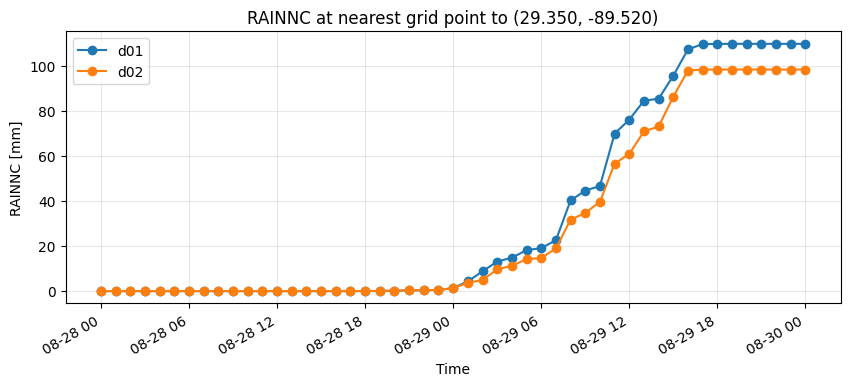

[OK] Saved figure → ICA06_plots\TS_WS10_29.350_-89.520.png


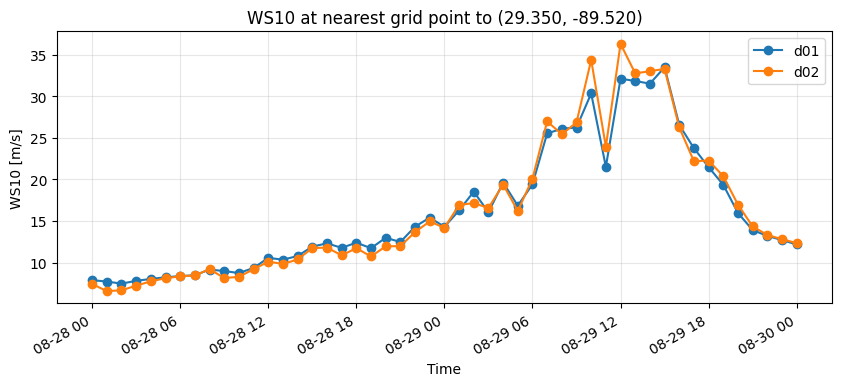

In [32]:
# Plot the time series for BOTH variables (RAINNC and WS10)


def clean_timeseries(t, y):
    """Return (t_clean, y_clean) with NaNs removed, sorted, and duplicate times dropped."""
    df = pd.DataFrame({"time": pd.to_datetime(t), "y": np.asarray(y)})
    df = df.dropna(subset=["time", "y"]).sort_values("time")
    df = df.drop_duplicates(subset="time", keep="first")
    return df["time"].to_numpy(), df["y"].to_numpy()


def plot_ts(t1, y1, t2, y2, title, ylabel, save_path):
    t1c, y1c = clean_timeseries(t1, y1)
    t2c, y2c = clean_timeseries(t2, y2)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(t1c, y1c, marker="o", label="d01")
    ax.plot(t2c, y2c, marker="o", label="d02")

    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()

    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H"))
    fig.autofmt_xdate()

    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    print(f"[OK] Saved figure → {save_path}")
    plt.show()


# RAINNC (accumulated precip, mm)
plot_ts(
    time_d01,
    rain_d01,
    time_d02,
    rain_d02,
    title=f"RAINNC at nearest grid point to ({lat0:.3f}, {lon0:.3f})",
    ylabel="RAINNC [mm]",
    save_path=PLOT_DIR / f"TS_RAINNC_{lat0:.3f}_{lon0:.3f}.png",
)

# WS10 (10 m wind speed, m/s)
plot_ts(
    time_d01,
    ws10_d01,
    time_d02,
    ws10_d02,
    title=f"WS10 at nearest grid point to ({lat0:.3f}, {lon0:.3f})",
    ylabel="WS10 [m/s]",
    save_path=PLOT_DIR / f"TS_WS10_{lat0:.3f}_{lon0:.3f}.png",
)
